## Analyzing a player's dismissals patterns, strengths and weaknesses

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np

In [4]:
# Load the comprehensive player data CSV file generated from JSON files
player_dismissal_file = 'data/ct17_final_squad_dismissal_summary.csv'
data = pd.read_csv(player_dismissal_file)

# Display the first few rows of the DataFrame
print(data.head())

    Player Name  Player ID          Grouping       Span  Dis  bwd  c fie  \
0  Fakhar Zaman     512191  right-arm bowler  2017-2023   56    9     33   
1  Fakhar Zaman     512191   left-arm bowler  2018-2023   16    5      6   
2  Fakhar Zaman     512191       unknown arm  2021-2023    3    0      0   
3  Fakhar Zaman     512191       pace bowler  2017-2023   46    9     30   
4  Fakhar Zaman     512191       spin bowler  2017-2023   26    5      9   

   c wk  st  lbw  hw  ro  oth  no     Ave  0s  Unnamed: 16  
0     8   4    2   0   0    0   0   32.80   6          NaN  
1     2   0    3   0   0    0   0   30.87   0          NaN  
2     0   0    0   0   3    0   0  134.33   0          NaN  
3     5   0    2   0   0    0   0   24.89   4          NaN  
4     5   4    3   0   0    0   0   45.61   2          NaN  


In [5]:
# Display the summary of the DataFrame
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 658 entries, 0 to 657
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Player Name  658 non-null    object 
 1   Player ID    658 non-null    int64  
 2   Grouping     658 non-null    object 
 3   Span         658 non-null    object 
 4   Dis          658 non-null    int64  
 5   bwd          658 non-null    int64  
 6   c fie        658 non-null    int64  
 7   c wk         658 non-null    int64  
 8   st           658 non-null    int64  
 9   lbw          658 non-null    int64  
 10  hw           658 non-null    int64  
 11  ro           658 non-null    int64  
 12  oth          658 non-null    int64  
 13  no           658 non-null    int64  
 14  Ave          658 non-null    object 
 15  0s           658 non-null    int64  
 16  Unnamed: 16  0 non-null      float64
dtypes: float64(1), int64(12), object(4)
memory usage: 87.5+ KB
None


## Extracting Player's Statistics

In [6]:
# Define the player name dynamically
player_name = "Babar Azam" #"V Kohli"  # Dynamic input for any player

# Check if the player name exists in the DataFrame
if player_name in data['Player Name'].values:
    # Filter the DataFrame to get all the stats for the selected player
    player_data = data[data['Player Name'] == player_name]

    # Display the data for the player
    print(f"Data for {player_name}:")
    print(player_data)
else:
    # Output an error message if the player is not found
    print(f"Error: Player '{player_name}' not found in the DataFrame.")
    # Raise an exception to stop further execution
    raise ValueError(f"Player '{player_name}' not found in the DataFrame.")


Data for Babar Azam:
    Player Name  Player ID           Grouping       Span  Dis  bwd  c fie  \
86   Babar Azam     348144   right-arm bowler  2015-2023   81   14     43   
87   Babar Azam     348144    left-arm bowler  2015-2023   17    3      9   
88   Babar Azam     348144        unknown arm  2018-2019    3    0      0   
89   Babar Azam     348144        pace bowler  2015-2023   64   12     36   
90   Babar Azam     348144        spin bowler  2015-2023   34    5     16   
91   Babar Azam     348144    mixture/unknown  2018-2019    3    0      0   
92   Babar Azam     348144     right-arm pace  2015-2023   55   12     30   
93   Babar Azam     348144     right-arm spin  2015-2023   26    2     13   
94   Babar Azam     348144      left-arm pace  2015-2023    9    0      6   
95   Babar Azam     348144      left-arm spin  2015-2023    8    3      3   
96   Babar Azam     348144    mixture/unknown  2018-2019    3    0      0   
97   Babar Azam     348144       2nd position  2015-201

# Analysis of Dismissal Types for the player

In [8]:
#Drop rows where 'Bowler Type' is 'mixture/unknown'
player_data_filtered = player_data[player_data['Grouping'] != 'mixture/unknown']

In [10]:
# List of dismissal types
dismissal_types = ['bwd', 'c fie', 'c wk', 'st', 'lbw', 'hw', 'ro']

# Aggregate dismissal counts
dismissal_counts = player_data[dismissal_types].sum()

# Display the aggregated dismissal counts
print(dismissal_counts)

bwd      102
c fie    312
c wk      72
st        30
lbw       72
hw         0
ro        18
dtype: int64


A pie chart visualization will display the different ways the player has been dismissed, showing the proportion of each dismissal type. This chart provides a clear and concise view of the frequency of each dismissal type

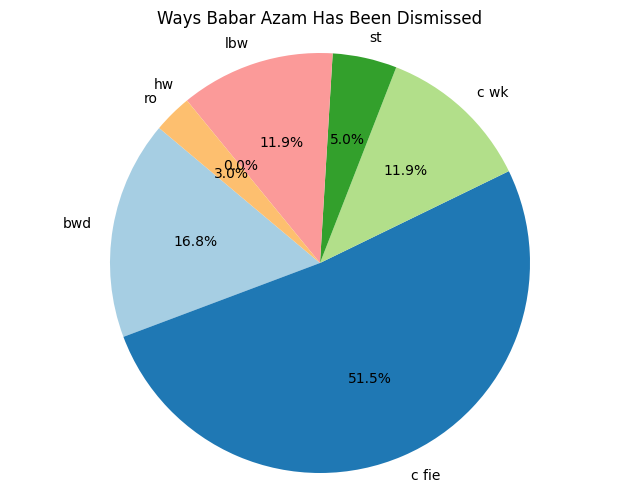

In [11]:
# pie chart
plt.figure(figsize=(8, 6))
plt.pie(dismissal_counts, labels=dismissal_counts.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(dismissal_counts))), startangle=140)
plt.title(f'Ways {player_name} Has Been Dismissed')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

Dismissal of player in all scenarios

In [18]:
# Aggregate dismissal counts by bowler type
all_scenarios_dismissal = player_data_filtered.groupby('Grouping')[dismissal_types].sum().reset_index()

# Display the aggregated dismissal counts
print(all_scenarios_dismissal)

             Grouping  bwd  c fie  c wk  st  lbw  hw  ro
0              0 runs    0      2     0   0    2   0   0
1            1-9 runs    0      5     1   1    3   0   2
2          10-19 runs    5      7     3   0    1   0   0
3        100-149 runs    1     10     2   0    0   0   0
4        150-199 runs    0      2     0   0    0   0   0
5          20-29 runs    1      1     2   1    1   0   0
6        2nd position    0      1     0   0    1   0   0
7          30-39 runs    3      7     1   0    1   0   0
8        3rd position   14     44    11   5    9   0   3
9          40-49 runs    4      2     1   0    1   0   0
10       4th position    3      7     1   0    2   0   0
11         50-89 runs    3     13     2   3    2   0   1
12       6th position    0      0     0   0    0   0   0
13         90-99 runs    0      3     0   0    1   0   0
14             bowled   17      0     0   0    0   0   0
15             caught    0     52    12   0    0   0   0
16    left-arm bowler    3     

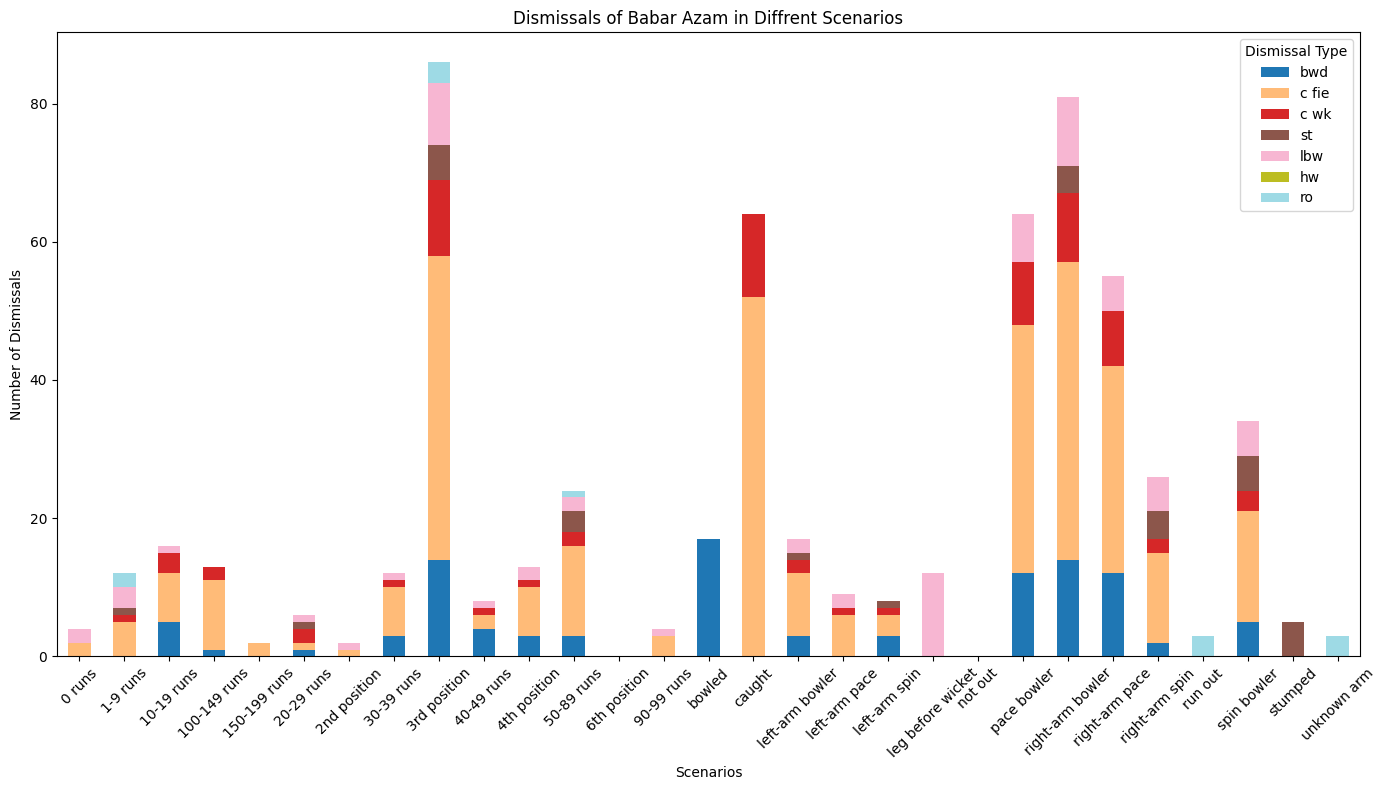

In [19]:
# Plot a stacked bar plot
all_scenarios_dismissal.set_index('Grouping')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')
plt.title(f'Dismissals of {player_name} in Diffrent Scenarios')
plt.xlabel('Scenarios')
plt.ylabel('Number of Dismissals')
plt.legend(title='Dismissal Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Dismissals of the player against diffrent bowler types

In [16]:
# Define the desired groupings
desired_groupings = ['left-arm pace', 'right-arm pace', 'left-arm spin', 'right-arm spin']

# Filter the DataFrame to include only the desired groupings
filtered_data = player_data_filtered[player_data_filtered['Grouping'].isin(desired_groupings)]

# Aggregate dismissal counts by bowler type
dismissals_by_bowler_type = filtered_data.groupby('Grouping')[dismissal_types].sum().reset_index()

# Display the aggregated dismissal counts
print(dismissals_by_bowler_type)

         Grouping  bwd  c fie  c wk  st  lbw  hw  ro
0   left-arm pace    0      6     1   0    2   0   0
1   left-arm spin    3      3     1   1    0   0   0
2  right-arm pace   12     30     8   0    5   0   0
3  right-arm spin    2     13     2   4    5   0   0


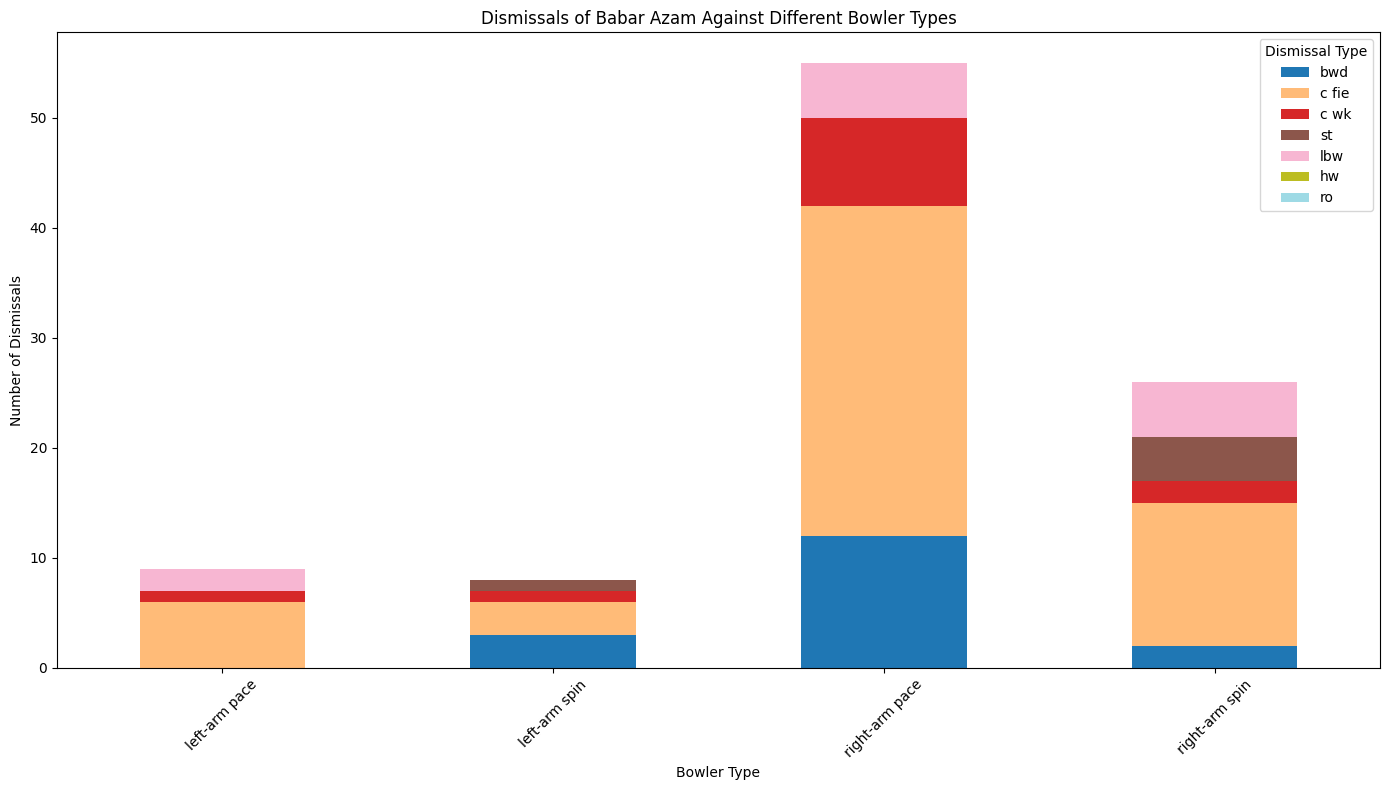

In [17]:
# Plot a stacked bar plot
dismissals_by_bowler_type.set_index('Grouping')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')
plt.title(f'Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Number of Dismissals')
plt.legend(title='Dismissal Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:
# dismissals_by_bowler_type.head
dismissals_by_bowler_type.columns

Index(['Grouping', 'bwd', 'c fie', 'c wk', 'st', 'lbw', 'hw', 'ro'], dtype='object')

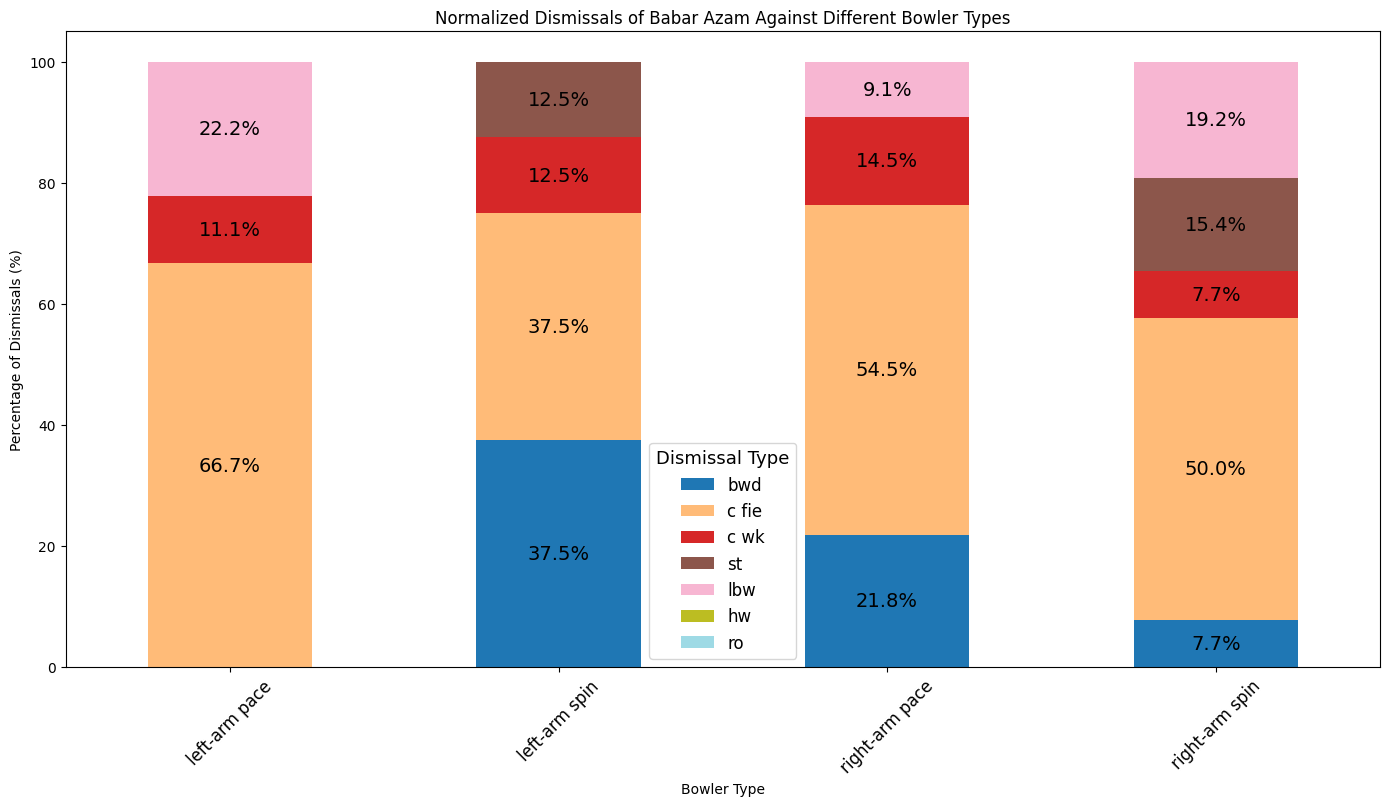

In [21]:
# Calculate total dismissals for each bowler type
dismissals_by_bowler_type['Total Dismissals'] = dismissals_by_bowler_type[dismissal_types].sum(axis=1)

# Normalize each dismissal type by the total dismissals for that bowler type
for dismissal_type in dismissal_types:
    dismissals_by_bowler_type[dismissal_type] = (dismissals_by_bowler_type[dismissal_type] / dismissals_by_bowler_type['Total Dismissals']) * 100

# Drop the total dismissals column as it's no longer needed
dismissals_by_bowler_type.drop(columns='Total Dismissals', inplace=True)

# Plot the normalized stacked bar plot
ax = dismissals_by_bowler_type.set_index('Grouping')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

# Add labels and title
plt.title(f'Normalized Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Percentage of Dismissals (%)')
plt.xticks(rotation=45)
plt.tight_layout()

# Add percentage labels within the bars
for i in range(dismissals_by_bowler_type.shape[0]):
    bottom = 0
    for j, col in enumerate(dismissal_types):
        value = dismissals_by_bowler_type.iloc[i][col]
        if value > 0:
            ax.text(i, bottom + value / 2, f'{value:.1f}%', ha='center', va='center', color='black', fontsize=14)
        bottom += value

ax.legend(title='Dismissal Type', title_fontsize=13, fontsize=12)
ax.tick_params(axis='x', labelsize=12)

# Show the plot
plt.show()


Normalizing the dismissals by each bowler against the player with the balls faced

In [23]:
# Aggregate total dismissals and balls faced by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Grouping')['Dis'].sum().reset_index()
balls_faced_by_bowler_type = player_data_filtered.groupby('Grouping')['BF'].sum().reset_index()

# Merge the two DataFrames
dismissals_balls = pd.merge(dismissals_by_bowler_type, balls_faced_by_bowler_type, on='Bowler Type')

# Calculate dismissal rate per ball faced
dismissals_balls['Dismissal Rate'] = dismissals_balls['Dis'] / dismissals_balls['BF']

# Display the normalized dismissal rates
print(dismissals_balls)

KeyError: 'Column not found: BF'

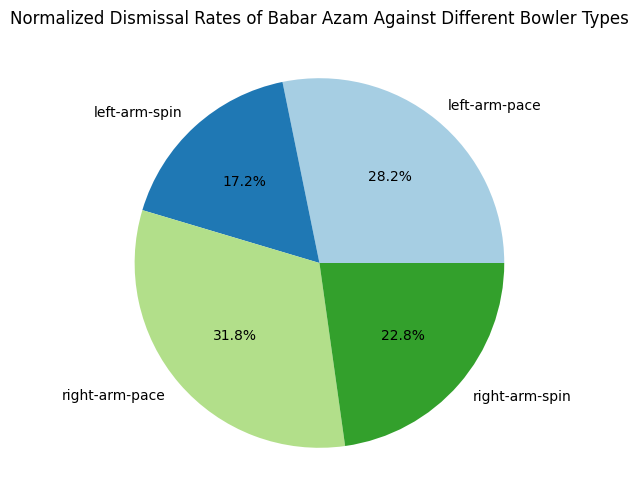

In [33]:
# Prepare data for pie plot
pie_data = dismissals_balls.set_index('Grouping')['Dismissal Rate']

# Plot a pie chart
plt.figure(figsize=(8, 6))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(pie_data))))
plt.title(f'Normalized Dismissal Rates of {player_name} Against Different Bowler Types')
plt.show()